# 02 — Generación reproducible de escenarios de faltantes

Este cuaderno prepara **ajuste, validación y prueba** sin inventar datos: divide cronológicamente el tramo 2018 en ajuste (80 %) y validación (20 %), y reserva el tramo 2019 completo para prueba externa. El filtro de noches anómalas se aplica **antes** de dividir y generar las máscaras.

- `ajuste`: primera parte de 2018, usada para entrenar.
- `validacion`: parte final de 2018, usada para elegir hiperparámetros.
- `evaluacion` (prueba): 2019, usada una sola vez al final.

Las máscaras guardan el índice temporal exacto y el orden de columnas. El cuaderno 03 comprueba esa alineación y **no vuelve a recortar** las máscaras. Ejecuta las celdas en orden.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

TRAMOS = Path("../data/gold/tramos")
SALIDA = Path("../data/gold/mascaras")
SALIDA.mkdir(parents=True, exist_ok=True)

LUZ = "Light(lux)"
NOCHE_INI, NOCHE_FIN = 19, 5
UMBRAL_LUZ_NOCHE = 5.0
PROPORCION_AJUSTE_2018 = 0.80

def leer_tramo(nombre):
    df = pd.read_csv(TRAMOS / nombre, index_col="Time_dt", parse_dates=["Time_dt", "Time_original"])
    df.index = pd.DatetimeIndex(df.index, name="Time_dt")
    if not df.index.is_monotonic_increasing or not df.index.is_unique:
        raise ValueError(f"Índice temporal desordenado o duplicado: {nombre}")
    return df

def es_noche(idx):
    return (idx.hour >= NOCHE_INI) | (idx.hour < NOCHE_FIN)

def filas_noche_anomala(df):
    if LUZ not in df.columns:
        raise KeyError(f"No existe la columna requerida {LUZ!r}")
    noche = es_noche(df.index)
    # 00:00–04:59 se asigna a la noche del día anterior; 19:00–23:59 al día actual.
    id_noche = df.index.normalize() - pd.to_timedelta((df.index.hour < NOCHE_FIN).astype(int), unit="D")
    malas = pd.Index(id_noche[noche & df[LUZ].gt(UMBRAL_LUZ_NOCHE).fillna(False).to_numpy()]).unique()
    return noche & id_noche.isin(malas)

def filtrar_noches(df, etiqueta):
    excluir = filas_noche_anomala(df)
    limpio = df.loc[~excluir].copy()
    assert not (es_noche(limpio.index) & limpio[LUZ].gt(UMBRAL_LUZ_NOCHE).fillna(False).to_numpy()).any()
    resumen = {"tramo": etiqueta, "filas_originales": len(df), "filas_eliminadas": int(excluir.sum()),
               "filas_finales": len(limpio), "pct_eliminado": round(100*excluir.mean(), 2)}
    return limpio, resumen

raw_2018 = leer_tramo("tramo_ajuste_2018.csv")
raw_2019 = leer_tramo("tramo_evaluacion_2019.csv")
columnas_fuente = [c for c in raw_2018.columns if c != "Time_original"]
if [c for c in raw_2019.columns if c != "Time_original"] != columnas_fuente:
    raise ValueError("Los tramos 2018 y 2019 no tienen el mismo orden de columnas")

# Validar la frecuencia antes de filtrar; luego habrá huecos deliberados por las noches excluidas.
for nombre, df in [("2018", raw_2018), ("2019", raw_2019)]:
    delta = df.index.to_series().diff().dropna()
    if not (delta == pd.Timedelta("30min")).all():
        raise ValueError(f"{nombre}: se esperaba una frecuencia original exacta de 30 minutos")

limpio_2018, resumen_2018 = filtrar_noches(raw_2018, "2018")
limpio_2019, resumen_2019 = filtrar_noches(raw_2019, "2019")

corte = int(np.floor(len(limpio_2018) * PROPORCION_AJUSTE_2018))
if corte < 1 or len(limpio_2018) - corte < 1:
    raise ValueError("No hay suficientes filas en 2018 para crear ajuste y validación")

# División estrictamente cronológica: no se mezclan filas futuras con entrenamiento.
ajuste = limpio_2018.iloc[:corte].copy()
validacion = limpio_2018.iloc[corte:].copy()
evaluacion = limpio_2019.copy()  # prueba externa 2019

# Los bloques se generan dentro de cada partición, sin cruzar límites de split ni de año.
variables = [c for c in columnas_fuente if c != "Relative Pressure(hpa)"]
GRUPOS = {
    "interior": ["Indoor Temperature(°C)", "Indoor Humidity(%)"],
    "termohigrometro": ["Outdoor Temperature(°C)", "Outdoor Humidity(%)", "DewPoint(°C)", "WindChill(°C)"],
    "barometro": ["Relative Pressure(hpa)", "Absolute Pressure(hpa)"],
    "anemometro": ["Wind Speed(km/h)", "Gust(km/h)"],
    "pluviometro": ["Hour Rainfall(mm)"],
    "luz": ["Light(lux)"],
}
# Se mantienen todas las columnas en las máscaras para alinearlas con los datos fuente; 03 decide cuáles modelar.
variables_mascara = columnas_fuente
if sorted(sum(GRUPOS.values(), [])) != sorted(variables_mascara):
    raise ValueError("GRUPOS debe cubrir exactamente las variables fuente (excepto Time_original)")

print("Particiones temporales:")
for nombre, df in [("ajuste", ajuste), ("validacion", validacion), ("prueba/evaluacion", evaluacion)]:
    print(f"{nombre:18s} | {df.index.min()} -> {df.index.max()} | filas={len(df):,}")
display(pd.DataFrame([resumen_2018, resumen_2019]))
assert ajuste.index.max() < validacion.index.min()
assert validacion.index.max() < evaluacion.index.min()


Particiones temporales:
ajuste             | 2018-08-21 06:00:00 -> 2018-09-21 12:30:00 | filas=1,322
validacion         | 2018-09-21 13:00:00 -> 2018-09-30 12:00:00 | filas=331
prueba/evaluacion  | 2019-05-01 01:30:00 -> 2019-06-20 08:30:00 | filas=1,855


,tramo,filas_originales,filas_eliminadas,filas_finales,pct_eliminado
0,2018,1933,280,1653,14.49
1,2019,2415,560,1855,23.19


## 1. Diseño de escenarios

`True` significa que el valor se oculta. Los bloques se generan sin cruzar los límites temporales de cada partición. En `disjoint`, los inicios de bloques de cada grupo de sensores se sortean de forma independiente (puede existir solapamiento accidental entre grupos); por eso se interpreta como patrón **desfasado**, no como garantía matemática de cero solapamientos entre sensores.


In [6]:
PATRONES = ["overlap", "disjoint"]
Q = [1, 3, 6]
DURACIONES = {"1h": 2, "6h": 12, "1d": 48, "3d": 144, "7d": 336}
PORCENTAJES = [5, 10, 20, 30, 40, 50]
TOLERANCIA = 2.0
SEMILLAS_AJUSTE = range(1, 11)
SEMILLAS_VALIDACION = range(201, 211)
SEMILLAS_PRUEBA = range(101, 111)

def inicios_de_bloques(rng, m, k, p):
    """Genera k bloques de p filas no solapados dentro de una partición."""
    if k < 1 or m - k*p + 1 < k:
        raise ValueError("Cantidad de bloques imposible para la longitud disponible")
    s = np.sort(rng.choice(m-k*p+1, size=k, replace=False))
    return s + np.arange(k)*p

def generar_mascara(m, patron, q, p, pct, rng):
    """Retorna (máscara, grupos, k) o None si la combinación no es alcanzable."""
    for _ in range(300):
        grupos = list(rng.choice(list(GRUPOS), size=q, replace=False))
        n_cols = sum(len(GRUPOS[g]) for g in grupos)
        k = int(round(pct/100 * m * len(variables_mascara) / (n_cols*p)))
        if k < 1 or m-k*p+1 < k:
            continue
        mascara = np.zeros((m, len(variables_mascara)), dtype=bool)
        comunes = inicios_de_bloques(rng, m, k, p)
        for grupo in grupos:
            cols = [variables_mascara.index(c) for c in GRUPOS[grupo]]
            inicios = comunes if patron == "overlap" else inicios_de_bloques(rng, m, k, p)
            for inicio in inicios:
                mascara[inicio:inicio+p, cols] = True
        real = mascara.mean()*100
        if abs(real-pct) <= TOLERANCIA:
            return mascara, grupos, k
    return None

def generar_conjunto(df, semillas, nombre_particion):
    info, mascaras = [], []
    m = len(df)
    for patron in PATRONES:
        for q in Q:
            if patron == "overlap" and q == 1:
                continue
            for duracion, p in DURACIONES.items():
                for pct in PORCENTAJES:
                    for semilla in semillas:
                        rng = np.random.default_rng([int(semilla), PATRONES.index(patron), q, p, pct])
                        res = generar_mascara(m, patron, q, p, pct, rng)
                        if res is None:
                            continue
                        mascara, grupos, k = res
                        escenario_id = len(mascaras)
                        info.append({"id": escenario_id, "particion": nombre_particion, "patron": patron,
                                     "q": q, "duracion": duracion, "filas_bloque": p,
                                     "pct_objetivo": pct, "pct_real": round(mascara.mean()*100, 2),
                                     "bloques_por_sensor": k, "sensores": "|".join(grupos), "semilla": int(semilla)})
                        mascaras.append(mascara)
    if not mascaras:
        raise ValueError(f"No se pudieron generar escenarios para {nombre_particion}; revisa la longitud de la partición")
    return pd.DataFrame(info), np.stack(mascaras)


## 2. Generación y guardado con control de alineación

Los nombres de archivo se mantienen compatibles con el cuaderno 03. Cada `.npz` incluye `mascaras`, `columnas` y `time_index`; cada CSV de índice contiene el identificador del escenario y sus parámetros.


In [7]:
PARTICIONES = {
    "ajuste_v1": (ajuste, SEMILLAS_AJUSTE),
    "validacion_v1": (validacion, SEMILLAS_VALIDACION),
    "evaluacion_v2": (evaluacion, SEMILLAS_PRUEBA),
}

resumen_generacion = []
for nombre, (df, semillas) in PARTICIONES.items():
    info, mascaras = generar_conjunto(df, semillas, nombre)
    info.to_csv(SALIDA / f"indice_{nombre}.csv", index=False)
    np.savez_compressed(
        SALIDA / f"mascaras_{nombre}.npz",
        mascaras=mascaras,
        columnas=np.asarray(variables_mascara, dtype=str),
        time_index=np.asarray(df.index.astype(str), dtype=str),
    )
    resumen_generacion.append({"particion": nombre, "filas": len(df), "escenarios": len(info),
                               "forma_mascaras": str(mascaras.shape),
                               "pct_real_min": info["pct_real"].min(), "pct_real_max": info["pct_real"].max()})
    print(f"{nombre}: {len(info):,} escenarios | forma={mascaras.shape} | guardado OK")
display(pd.DataFrame(resumen_generacion))


ajuste_v1: 1,150 escenarios | forma=(1150, 1322, 12) | guardado OK
validacion_v1: 790 escenarios | forma=(790, 331, 12) | guardado OK
evaluacion_v2: 1,170 escenarios | forma=(1170, 1855, 12) | guardado OK


,particion,filas,escenarios,forma_mascaras,pct_real_min,pct_real_max
0,ajuste_v1,1322,1150,"(1150, 1322, 12)",3.63,50.83
1,validacion_v1,331,790,"(790, 331, 12)",3.63,50.76
2,evaluacion_v2,1855,1170,"(1170, 1855, 12)",3.88,51.75


## 3. Verificaciones finales

Se comprueba la forma de los arreglos, que los IDs sean consecutivos y que cada máscara corresponda exactamente al índice temporal que se guardó. Si no hay escenarios válidos para una partición corta, el cuaderno se detiene explícitamente en lugar de producir un archivo vacío.


ajuste_v1: alineación OK | 1150 escenarios | error porcentual máximo=1.88 pp
validacion_v1: alineación OK | 790 escenarios | error porcentual máximo=1.87 pp
evaluacion_v2: alineación OK | 1170 escenarios | error porcentual máximo=1.89 pp


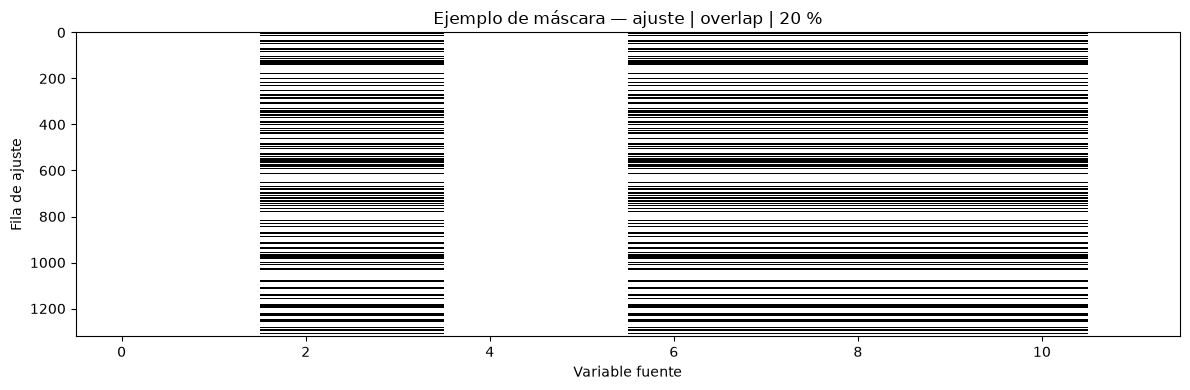

In [8]:
def longitudes_bloques(col):
    c = np.r_[0, col.astype(int), 0]
    d = np.diff(c)
    return np.where(d == -1)[0] - np.where(d == 1)[0]

def verificar_particion(nombre, df):
    with np.load(SALIDA / f"mascaras_{nombre}.npz") as z:
        masks, cols, tiempos = z["mascaras"], z["columnas"].tolist(), z["time_index"].astype(str)
    info = pd.read_csv(SALIDA / f"indice_{nombre}.csv")
    assert masks.ndim == 3
    assert masks.shape[1] == len(df) == len(tiempos)
    assert masks.shape[2] == len(cols) == len(variables_mascara)
    assert np.array_equal(tiempos, np.asarray(df.index.astype(str), dtype=str))
    assert info["id"].tolist() == list(range(len(info)))
    assert len(info) == masks.shape[0]
    errores = (info["pct_real"] - info["pct_objetivo"]).abs()
    print(f"{nombre}: alineación OK | {len(info)} escenarios | error porcentual máximo={errores.max():.2f} pp")
    return info, masks

INFO_AJUSTE, _ = verificar_particion("ajuste_v1", ajuste)
INFO_VALIDACION, _ = verificar_particion("validacion_v1", validacion)
INFO_PRUEBA, _ = verificar_particion("evaluacion_v2", evaluacion)

# Cargar solo una máscara para visualizar; evita mantener en RAM los tres arreglos completos.
seleccion = INFO_AJUSTE[(INFO_AJUSTE.patron == "overlap") & (INFO_AJUSTE.pct_objetivo == 20)]
if not seleccion.empty:
    sid = int(seleccion.iloc[0]["id"])
    with np.load(SALIDA / "mascaras_ajuste_v1.npz") as z:
        mascara_ejemplo = z["mascaras"][sid]
    plt.figure(figsize=(12, 4))
    plt.imshow(mascara_ejemplo, aspect="auto", cmap="Greys", interpolation="nearest")
    plt.title("Ejemplo de máscara — ajuste | overlap | 20 %")
    plt.xlabel("Variable fuente"); plt.ylabel("Fila de ajuste")
    plt.tight_layout(); plt.show()
